# AutoSplice · CocoGlide 근접 중복 추가 검사 — CNN 특징·좌우반전

- 작성자: seonghun
- 상태: **완료 — Colab 저장 출력 검토 완료 (2026-11-23), T05 분할 확정은 별도 진행**
- 작성일: 2026-11-23
- 관련 작업: T05 데이터셋 EDA·분할 확정
- [보고서](../../docs/eda/EXP_seonghun_002_near_duplicate_feature_check.md) · [기준 실험 보고서](../../docs/eda/EXP_seonghun_001_near_duplicate_check.md)

001은 perceptual hash로 리사이즈·재압축된 중복을 찾아 46217(train)–54313(val) 1쌍을 발견함. perceptual hash는 크롭·좌우반전·큰 편집·연속 촬영 사진에 약하므로, 이 노트북은 ImageNet 사전학습 ResNet-50의 특징 유사도와 좌우반전 비교를 추가해 남은 중복을 찾음.

분할을 다시 만들 때는 같은 split 안의 중복도 같은 묶음으로 다뤄야 하므로 **모든 쌍**을 비교함. 이 노트북은 중복 후보를 찾아 사람이 판단한 목록을 남기는 데까지만 함. 분할 CSV를 만들거나 수정하지 않음.

대상은 001과 같이 AutoSplice 정상 원본 2,273장과 CocoGlide 정상 512장임. test와 CocoGlide는 중복 검사에만 사용함. 유사도 기준값은 검토 후보를 고르는 용도이며 학습 설정이 아님.

팀원이 VS Code의 Colab 원격 커널에서 위에서부터 실행하고 출력이 포함된 노트북을 저장함. GPU 런타임을 권장하며 CPU에서도 실행할 수 있음.

## 1. Drive·공통 코드·실행 환경 준비

공유 Drive의 데이터 ZIP과 `AI_Forensics/project/scripts/`를 사용함. 실제 import 위치와 코드·분할 해시를 확인함. `preprocessing.py`의 기대 해시는 byhyun 002 작업이 반영된 현재 `main` 버전임. Drive 파일이 다르면 중단하고 버전을 확인해야 하며 기대 해시만 바꾸지 않음.

ResNet-50 사전학습 가중치는 torchvision에서 내려받음. 아래 버전은 실행 기록이며 팀 표준을 확정하는 셀이 아님.

In [1]:
from pathlib import Path
from google.colab import drive
import importlib
import importlib.metadata
import platform
import sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, features
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
drive.mount("/content/drive")
shared_root = Path("/content/drive/MyDrive/AI_Forensics")
project_root = shared_root / "project"
work_root = Path("/content")
data_root = work_root / "datasets"
split_path = project_root / "scripts/splits/autosplice_seed42.csv"
archive_paths = {
    "AutoSplice": shared_root / "datasets/AutoSplice/AutoSplice.zip",
    "CocoGlide": shared_root / "datasets/CocoGlide.zip",
}
extract_paths = {"AutoSplice": data_root, "CocoGlide": data_root / "CocoGlide"}
required = ["scripts/__init__.py", "scripts/datasets.py", "scripts/preprocessing.py", "scripts/splits/autosplice_seed42.csv"]
for relative in required:
    if not (project_root / relative).is_file():
        raise FileNotFoundError(f"Drive에 공통 파일을 업로드해야 함: {relative}")

sys.path.insert(0, str(project_root))
importlib.invalidate_caches()
import scripts
import scripts.datasets as dataset_module
import scripts.preprocessing as preprocessing_module

for module, relative in [(scripts, "scripts/__init__.py"), (dataset_module, "scripts/datasets.py"),
                         (preprocessing_module, "scripts/preprocessing.py")]:
    if Path(module.__file__).resolve() != (project_root / relative).resolve():
        raise ImportError(f"프로젝트의 모듈을 불러오도록 커널을 재시작해야 함: {relative}")
    print("불러온 코드:", module.__file__)

from scripts.datasets import sha256, prepare_dataset_zip, autosplice_records, cocoglide_records
from scripts.preprocessing import load_rgb

print("실행 시각 UTC:", datetime.now(timezone.utc).isoformat())
print("Python:", platform.python_version())
print("OS:", platform.platform())
for package in ("numpy", "Pillow", "pandas", "matplotlib", "torch", "torchvision"):
    print(package, importlib.metadata.version(package))
print("JPEG library:", features.version("jpg"))
print("프로젝트:", project_root)

Mounted at /content/drive
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/__init__.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/datasets.py
불러온 코드: /content/drive/MyDrive/AI_Forensics/project/scripts/preprocessing.py
실행 시각 UTC: 2026-11-23T11:27:05.997196+00:00
Python: 3.13.16
OS: Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6
Pillow 11.3.0
pandas 2.2.3
matplotlib 3.10.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
JPEG library: 6.2
프로젝트: /content/drive/MyDrive/AI_Forensics/project


In [2]:
expected_files = {
    "scripts/__init__.py": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855",
    "scripts/datasets.py": "435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88",
    "scripts/preprocessing.py": "73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f",
    "scripts/splits/autosplice_seed42.csv": "f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e",
}
for relative, expected_hash in expected_files.items():
    actual_hash = sha256(project_root / relative)
    print(relative, actual_hash)
    if actual_hash != expected_hash:
        raise ValueError(f"검토한 코드·분할 버전과 일치해야 함: {relative}")

image_size = 224
batch_size = 64
cosine_threshold = 0.90
phash_threshold = 10
review_top_k = 60
plot_limit = 60
table_limit = 300
known_pair = ("46217", "54313")
settings = dict(image_size=image_size, batch_size=batch_size, cosine_threshold=cosine_threshold, phash_threshold=phash_threshold,
                review_top_k=review_top_k, plot_limit=plot_limit, table_limit=table_limit, known_pair=known_pair)
print("검사 설정:", settings)
print("cosine_threshold·phash_threshold는 검토 후보 기준이며 학습 설정이 아님")

scripts/__init__.py e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855
scripts/datasets.py 435215ef08c2c43ce2f84795d783895074eee85f8e062f28ea8ee6acabad3e88
scripts/preprocessing.py 73ce7fa0aee3f2b901a9ab04d430ff8ae2bcaa7262005600f6b08f04b95c652f
scripts/splits/autosplice_seed42.csv f8a2893ab93b82264e6434fa0c26f09472de05bd98829065c2a0db846ace7b1e
검사 설정: {'image_size': 224, 'batch_size': 64, 'cosine_threshold': 0.9, 'phash_threshold': 10, 'review_top_k': 60, 'plot_limit': 60, 'table_limit': 300, 'known_pair': ('46217', '54313')}
cosine_threshold·phash_threshold는 검토 후보 기준이며 학습 설정이 아님


## 2. 데이터 ZIP 준비

001과 같은 ZIP·공통 함수를 사용함. 기존 완료 표시가 있으면 해제 파일을 재사용하며 그 여부를 출력으로 남김.

In [3]:
archive_hashes = {
    "AutoSplice": "0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36",
    "CocoGlide": "fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9",
}
for name, source in archive_paths.items():
    prepare_dataset_zip(source, work_root / f"{name}.zip", extract_paths[name], archive_hashes[name])
    print(name, "ZIP SHA-256:", archive_hashes[name])

AutoSplice ZIP SHA-256 확인 및 압축 해제 완료
AutoSplice ZIP SHA-256: 0d94e2df6842f44c11e21ee207707c49fd9717ec89048bd6f28fc1e07c4a5e36
CocoGlide ZIP SHA-256 확인 및 압축 해제 완료
CocoGlide ZIP SHA-256: fc848643ad0a81010ba2a6ab8c055762782f54e4fb9e407210dbfe1c3b538af9


## 3. 검사 대상 목록

001과 같은 대상임. AutoSplice는 고정 분할 CSV로 원본 ID별 split을 연결한 정상 원본, CocoGlide는 table.csv의 정상 이미지를 사용함.

In [4]:
auto = [row for row in autosplice_records(data_root / "AutoSplice", split_path, quality=100) if row["kind"] == "normal"]
coco = [row for row in cocoglide_records(data_root / "CocoGlide") if row["kind"] == "normal"]
targets = pd.DataFrame(auto + coco)
targets["group"] = np.where(targets["dataset"] == "AutoSplice", "AutoSplice_" + targets["split"], "CocoGlide")
counts = targets.groupby("group").size().to_dict()
print("대상 수:", counts)
expected_counts = {"AutoSplice_train": 1818, "AutoSplice_val": 227, "AutoSplice_test": 228, "CocoGlide": 512}
if counts != expected_counts:
    raise ValueError("001에서 확인한 대상 수와 일치해야 함.")
if targets["image_path"].duplicated().any():
    raise ValueError("대상 이미지 경로는 중복되지 않아야 함.")

대상 수: {'AutoSplice_test': 228, 'AutoSplice_train': 1818, 'AutoSplice_val': 227, 'CocoGlide': 512}


## 4. 특징·해시 계산

- CNN 특징: torchvision ResNet-50(`IMAGENET1K_V2`)의 마지막 전역 평균 풀링 출력 2,048차원을 사용함. 이미지를 자르지 않고 224×224로 축소한 뒤 ImageNet 평균·표준편차로 정규화함. 원본과 좌우반전 이미지의 특징을 모두 구하고 길이를 1로 맞춤.
- pHash: 001과 같은 계산(회색조, 32×32 DCT, 저주파 8×8)을 원본과 좌우반전 이미지에 적용함.

CNN 특징은 이미지의 내용이 비슷하면 가까워지므로 크롭·편집·색 보정에도 비교적 강함. 같은 종류의 물체를 찍은 다른 사진도 가까워질 수 있으므로 사람이 그림으로 판단해야 함.

In [5]:
import torch
import torchvision
from torchvision.models import ResNet50_Weights, resnet50

device = "cuda" if torch.cuda.is_available() else "cpu"
print("장치:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")
weights = ResNet50_Weights.IMAGENET1K_V2
model = resnet50(weights=weights)
model.fc = torch.nn.Identity()
model = model.eval().to(device)
mean = torch.tensor(weights.transforms().mean).view(1, 3, 1, 1).to(device)
std = torch.tensor(weights.transforms().std).view(1, 3, 1, 1).to(device)
print("가중치:", weights)


def dct_matrix(size):
    k = np.arange(size)[:, None]
    n = np.arange(size)[None, :]
    matrix = np.cos(np.pi * (2 * n + 1) * k / (2 * size)) * np.sqrt(2 / size)
    matrix[0] /= np.sqrt(2)
    return matrix


DCT = dct_matrix(32)


def phash(image):
    pixels = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float64)
    low = (DCT @ pixels @ DCT.T)[:8, :8].ravel()
    return low > np.median(low[1:])


@torch.no_grad()
def embed(images):
    batch = np.stack([np.asarray(image.resize((image_size, image_size), Image.Resampling.BILINEAR)) for image in images])
    tensor = torch.from_numpy(batch).permute(0, 3, 1, 2).float().div(255).to(device)
    output = model((tensor - mean) / std)
    return torch.nn.functional.normalize(output, dim=1).cpu().numpy()


feature_parts, flip_parts, phash_bits, phash_flip_bits, sizes = [], [], [], [], []
paths = list(targets["image_path"])
for start in range(0, len(paths), batch_size):
    images = [Image.fromarray(load_rgb(path)) for path in paths[start : start + batch_size]]
    flipped = [ImageOps.mirror(image) for image in images]
    feature_parts.append(embed(images))
    flip_parts.append(embed(flipped))
    phash_bits.extend(phash(image) for image in images)
    phash_flip_bits.extend(phash(image) for image in flipped)
    sizes.extend(f"{image.height}x{image.width}" for image in images)
    if start // batch_size % 10 == 0:
        print(f"{start + len(images)} / {len(paths)}")

targets["size"] = sizes
feats = np.concatenate(feature_parts)
feats_flip = np.concatenate(flip_parts)
phash_bits = np.array(phash_bits, dtype=np.int32)
phash_flip_bits = np.array(phash_flip_bits, dtype=np.int32)
print("특징:", feats.shape, "/ 반전 특징:", feats_flip.shape, "/ pHash:", phash_bits.shape)

장치: cuda Tesla T4
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 127MB/s]


가중치: ResNet50_Weights.IMAGENET1K_V2
64 / 2785
704 / 2785
1344 / 2785
1984 / 2785
2624 / 2785
특징: (2785, 2048) / 반전 특징: (2785, 2048) / pHash: (2785, 64)


## 5. 유사도와 후보

- 특징 유사도: 두 이미지의 코사인 유사도와, 한쪽을 좌우반전했을 때의 코사인 유사도 중 큰 값을 사용함. 1에 가까울수록 비슷함.
- pHash 거리: 원본끼리와 한쪽을 좌우반전했을 때의 해밍 거리 중 작은 값을 사용함.

특징 유사도가 기준값 이상이거나 pHash 거리가 기준값 이하이면 후보로 표시함. 같은 그룹 안의 쌍도 후보에 포함함. 001에서 찾은 46217–54313의 값을 함께 출력해 방법이 이 쌍을 찾는지 확인함.

001 발견 쌍 ('46217', '54313'): 특징 유사도 0.9921, pHash 0
후보 쌍(전체): 55 / 그중 그룹 간: 11


,group_a,group_b,kind,pairs,candidates,max_similarity,min_phash
0,AutoSplice_train,AutoSplice_train,같은 그룹,1651653,40,1.0000,0
1,AutoSplice_train,AutoSplice_val,그룹 간,412686,4,0.9921,0
2,AutoSplice_train,AutoSplice_test,그룹 간,414504,5,0.9144,10
3,AutoSplice_train,CocoGlide,그룹 간,930816,1,0.8415,10
4,AutoSplice_val,AutoSplice_val,같은 그룹,25651,0,0.8633,14
5,AutoSplice_val,AutoSplice_test,그룹 간,51756,1,0.9198,12
6,AutoSplice_val,CocoGlide,그룹 간,116224,0,0.8221,12
7,AutoSplice_test,AutoSplice_test,같은 그룹,25878,1,0.9041,12
8,AutoSplice_test,CocoGlide,그룹 간,116736,0,0.7733,12
9,CocoGlide,CocoGlide,같은 그룹,130816,3,0.9456,14


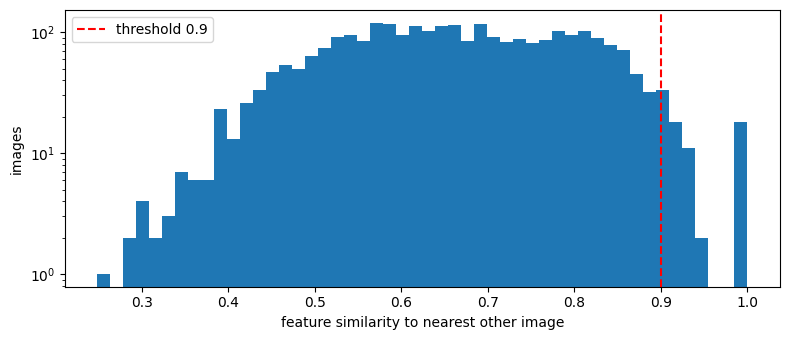

최근접 특징 유사도 요약:


,count,mean,std,min,50%,90%,99%,max
nearest_similarity,2785.0,0.6642,0.1339,0.2482,0.6609,0.8395,0.9276,1.0


In [6]:
def hamming(a, b):
    return a @ (1 - b).T + (1 - a) @ b.T


cosine = feats @ feats.T
cosine_flip = feats @ feats_flip.T
similarity = np.maximum(cosine, np.maximum(cosine_flip, cosine_flip.T))
phash_dist = np.minimum(hamming(phash_bits, phash_bits), hamming(phash_bits, phash_flip_bits))
phash_dist = np.minimum(phash_dist, phash_dist.T)
flipped_better = np.maximum(cosine_flip, cosine_flip.T) > cosine
groups = targets["group"].to_numpy()
upper = np.triu(np.ones(similarity.shape, dtype=bool), k=1)
cross = groups[:, None] != groups[None, :]
close = upper & ((similarity >= cosine_threshold) | (phash_dist <= phash_threshold))

ids = targets["original_id"].astype(str).to_numpy()
known_i = int(np.flatnonzero((ids == known_pair[0]) & (targets["dataset"] == "AutoSplice"))[0])
known_j = int(np.flatnonzero((ids == known_pair[1]) & (targets["dataset"] == "AutoSplice"))[0])
print(f"001 발견 쌍 {known_pair}: 특징 유사도 {similarity[known_i, known_j]:.4f}, pHash {phash_dist[known_i, known_j]}")

summary_rows = []
names = list(expected_counts)
for a_index, a in enumerate(names):
    for b in names[a_index:]:
        mask = upper & (groups[:, None] == a) & (groups[None, :] == b) if a == b else ((groups[:, None] == a) & (groups[None, :] == b))
        summary_rows.append(dict(group_a=a, group_b=b, kind="같은 그룹" if a == b else "그룹 간", pairs=int(mask.sum()),
                                 candidates=int((mask & ((similarity >= cosine_threshold) | (phash_dist <= phash_threshold))).sum()),
                                 max_similarity=round(float(similarity[mask].max()), 4) if mask.any() else None,
                                 min_phash=int(phash_dist[mask].min()) if mask.any() else None))
print("후보 쌍(전체):", int(close.sum()), "/ 그중 그룹 간:", int((close & cross).sum()))
display(pd.DataFrame(summary_rows))

masked = np.where(np.eye(len(similarity), dtype=bool), -1, similarity)
nearest = masked.max(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(nearest, bins=np.linspace(min(0.5, nearest.min()), 1.0, 51))
ax.axvline(cosine_threshold, color="red", linestyle="--", label=f"threshold {cosine_threshold}")
ax.set_xlabel("feature similarity to nearest other image")
ax.set_ylabel("images")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()
print("최근접 특징 유사도 요약:")
display(pd.Series(nearest).describe(percentiles=[0.5, 0.9, 0.99]).round(4).to_frame("nearest_similarity").T)

## 6. 사람 검토용 쌍

기준 이하·이상 후보 전부와, 기준과 상관없이 특징 유사도가 가장 높은 상위 쌍을 함께 보여줌. 유사도가 높은 순으로 정렬함. 같은 장면을 같은 순간에 찍은 사진(크기·크롭·반전·압축·색만 다른 경우)이면 중복으로 판단함. 같은 인물·장소·물체라도 다른 순간에 찍은 다른 사진이면 중복이 아님. `flipped`가 True이면 좌우반전했을 때 더 비슷하다는 뜻임.

검토 쌍: 71 / 기준 후보: 55 / 그중 그룹 간: 11


,similarity,phash,flipped,candidate,i_group,i_id,i_file,i_size,j_group,j_id,j_file,j_size,same_group
0,1.0000,0,False,True,AutoSplice_train,46661,46661.jpg,256x384,AutoSplice_train,62585,62585.jpg,256x384,True
1,0.9999,0,False,True,AutoSplice_train,56466,56466.jpg,256x370,AutoSplice_train,58359,58359.jpg,256x370,True
2,0.9998,0,False,True,AutoSplice_train,49708,49708.jpg,294x256,AutoSplice_train,59174,59174.jpg,294x256,True
3,0.9980,0,False,True,AutoSplice_train,54456,54456.jpg,256x383,AutoSplice_train,61217,61217.jpg,256x383,True
4,0.9956,0,False,True,AutoSplice_train,52710,52710.jpg,256x368,AutoSplice_train,56108,56108.jpg,256x368,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,0.1218,10,False,True,AutoSplice_train,47661,47661.jpg,256x387,CocoGlide,85665,kite_85665.png,256x256,False
67,0.1134,10,True,True,AutoSplice_train,40274,40274.jpg,256x384,AutoSplice_train,51677,51677.jpg,256x383,True
68,0.1023,10,True,True,AutoSplice_test,57331,57331.jpg,256x383,AutoSplice_train,72958,72958.jpg,256x420,False
69,0.0927,10,False,True,AutoSplice_train,39576,39576.jpg,307x256,AutoSplice_train,43915,43915.jpg,256x368,True


그림은 유사도 순 상위 60쌍만 표시함. 나머지는 위 표에서 확인해야 함





In [7]:
pair_i, pair_j = np.nonzero(close)
top_i, top_j = np.nonzero(upper)
order = np.argsort(-similarity[upper], kind="stable")[:review_top_k]
review = pd.DataFrame(dict(i=np.concatenate([pair_i, top_i[order]]), j=np.concatenate([pair_j, top_j[order]]))).drop_duplicates()
review["similarity"] = similarity[review["i"], review["j"]].round(4)
review["phash"] = phash_dist[review["i"], review["j"]]
review["flipped"] = flipped_better[review["i"], review["j"]] | flipped_better[review["j"], review["i"]]
review["candidate"] = (review["similarity"] >= cosine_threshold) | (review["phash"] <= phash_threshold)
review = review.sort_values(["similarity", "phash", "i", "j"], ascending=[False, True, True, True]).reset_index(drop=True)
for side in ("i", "j"):
    info = targets.iloc[review[side]].reset_index(drop=True)
    review[f"{side}_group"] = info["group"]
    review[f"{side}_id"] = info["original_id"]
    review[f"{side}_file"] = info["image_path"].map(lambda p: p.name)
    review[f"{side}_size"] = info["size"]
review["same_group"] = review["i_group"] == review["j_group"]
print("검토 쌍:", len(review), "/ 기준 후보:", int(review["candidate"].sum()), "/ 그중 그룹 간:", int((review["candidate"] & ~review["same_group"]).sum()))
if len(review) > table_limit:
    print(f"표는 유사도 순 상위 {table_limit}쌍만 표시함")
display(review.drop(columns=["i", "j"]).head(table_limit))

shown = review.head(plot_limit)
if len(review) > plot_limit:
    print(f"그림은 유사도 순 상위 {plot_limit}쌍만 표시함. 나머지는 위 표에서 확인해야 함")
fig, axes = plt.subplots(len(shown), 2, figsize=(8, 3.2 * len(shown)), squeeze=False)
for number, (axes_row, pair) in enumerate(zip(axes, shown.itertuples())):
    for ax, side in zip(axes_row, ("i", "j")):
        row = targets.iloc[getattr(pair, side)]
        ax.imshow(load_rgb(row["image_path"]))
        ax.set_title(f"#{number} {row['group']} / {row['image_path'].name}\nsim {pair.similarity:.3f} pHash {pair.phash} flip {pair.flipped}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 7. 결과 정리

자동 검사 결과를 요약함. 팀원은 6절 그림에서 같은 사진으로 판단한 쌍의 번호(`#`)와 ID·그룹을 아래 검토 메모에 적고 출력이 포함된 파일을 저장함. 이 목록은 분할을 다시 만드는 담당자에게 전달함.

In [8]:
result_summary = {
    "대상 수": counts,
    "후보 쌍(전체)": int(close.sum()),
    "후보 쌍(그룹 간)": int((close & cross).sum()),
    "검토용 표시 쌍": len(review),
    "001 발견 쌍 특징 유사도": round(float(similarity[known_i, known_j]), 4),
}
for key, value in result_summary.items():
    print(f"{key}: {value}")

대상 수: {'AutoSplice_test': 228, 'AutoSplice_train': 1818, 'AutoSplice_val': 227, 'CocoGlide': 512}
후보 쌍(전체): 55
후보 쌍(그룹 간): 11
검토용 표시 쌍: 71
001 발견 쌍 특징 유사도: 0.9921


### 사람의 검토 메모

- 같은 사진으로 판단한 쌍(# 번호·ID·그룹·이유): 미확인
- 그룹 간 중복(누수) 여부: 미확인
- 같은 그룹 안의 중복: 미확인
- 분할 담당자에게 전달할 중복 묶음: 미정

[개별 보고서](../../docs/eda/EXP_seonghun_002_near_duplicate_feature_check.md) · [001 보고서](../../docs/eda/EXP_seonghun_001_near_duplicate_check.md) · [TODO](../../TODO.md)